# Tugas Deep Reinforcement Learning 

| Nama              | NRP        |
|-------------------|------------|
| Muhammad Dayyan Ghazanfar Latief         | 5054241036     |

In [34]:
!pip3 install gymnasium[classic_control]


[notice] A new release of pip is available: 25.3 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [35]:
# Import Library
import gymnasium as gym
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import random
import matplotlib.pyplot as plt
from collections import deque

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Menggunakan device: {device}")

Menggunakan device: cpu


In [36]:
# Hyperparameter
GAMMA        = 0.99      
LR           = 1e-3      
BATCH_SIZE   = 64        
BUFFER_SIZE  = 10_000    
MIN_BUFFER   = 1_000     
EPSILON_START = 1.0      
EPSILON_END   = 0.05     
EPSILON_DECAY = 0.995    
TARGET_UPDATE = 10       
NUM_EPISODES  = 500      

In [37]:
# Replay Buffer
class ReplayBuffer:
    """
    Menyimpan pengalaman (s, a, r, s', done) agent selama interaksi.
    Menggunakan deque agar otomatis menghapus data lama jika penuh.
    """
    def __init__(self, capacity):
        self.buffer = deque(maxlen=capacity)

    def push(self, state, action, reward, next_state, done):
        self.buffer.append((state, action, reward, next_state, done))

    def sample(self, batch_size):
        """
        Ambil batch secara acak dari buffer.
        Return: masing-masing komponen dalam bentuk tensor PyTorch.
        """
        batch = random.sample(self.buffer, batch_size)

        states, actions, rewards, next_states, dones = zip(*batch)

        states      = torch.tensor(np.array(states),      dtype=torch.float32).to(device)
        actions     = torch.tensor(np.array(actions),     dtype=torch.long).to(device)
        rewards     = torch.tensor(np.array(rewards),     dtype=torch.float32).to(device)
        next_states = torch.tensor(np.array(next_states), dtype=torch.float32).to(device)
        dones       = torch.tensor(np.array(dones),       dtype=torch.float32).to(device)

        return states, actions, rewards, next_states, dones

    def __len__(self):
        return len(self.buffer)

In [38]:
# Arsitektur Neural Network DQN
class DQN(nn.Module):
    """
    Deep Q-Network: MLP sederhana dengan 2 hidden layer.
    
    Input  : state (4 angka untuk CartPole)
    Output : Q-value untuk setiap aksi (2 aksi untuk CartPole)
    """
    def __init__(self, state_dim, action_dim):
        super(DQN, self).__init__()

        self.network = nn.Sequential(
            nn.Linear(state_dim, 128),   
            nn.ReLU(),                   
            nn.Linear(128, 128),         
            nn.ReLU(),                   
            nn.Linear(128, action_dim),  
        )

    def forward(self, x):
        return self.network(x)

In [39]:
# Epsilon-Greedy
def select_action(state, policy_net, epsilon, action_dim):
    """
    Pilih aksi menggunakan strategi epsilon-greedy.
    
    - Dengan prob epsilon  → aksi RANDOM (eksplorasi)
    - Dengan prob 1-epsilon → aksi terbaik dari policy_net (eksploitasi)
    
    Args:
        state      : numpy array state saat ini
        policy_net : neural network yang digunakan
        epsilon    : probabilitas eksplorasi saat ini
        action_dim : jumlah aksi yang tersedia
    
    Returns:
        action (int): aksi yang dipilih (0 atau 1)
    """
    if random.random() < epsilon:
        # Eksplorasi: pilih aksi secara acak
        return random.randint(0, action_dim - 1)
    else:
        # Eksploitasi: pilih aksi dengan Q-value tertinggi
        state_tensor = torch.tensor(state, dtype=torch.float32).unsqueeze(0).to(device)
        with torch.no_grad():          
            q_values = policy_net(state_tensor)
        return q_values.argmax(dim=1).item()

In [40]:
# Optimize Model
def optimize_model(policy_net, target_net, optimizer, replay_buffer):
    if len(replay_buffer) < MIN_BUFFER:
        return None

    # Step 1: Sample batch dari replay buffer
    states, actions, rewards, next_states, dones = replay_buffer.sample(BATCH_SIZE)

    # Step 2: Hitung Q-value prediksi dari policy_net
    q_values = policy_net(states).gather(1, actions.unsqueeze(1)).squeeze(1)

    # Step 3: Hitung TD Target menggunakan target_net
    with torch.no_grad():
        max_next_q = target_net(next_states).max(dim=1).values
        td_target = rewards + GAMMA * max_next_q * (1 - dones)

    # Step 4: Hitung Loss (MSE antara prediksi vs target)
    loss = nn.MSELoss()(q_values, td_target)

    # Step 5: Backpropagation
    optimizer.zero_grad()   
    loss.backward()         

    # Gradient clipping: cegah gradien terlalu besar 
    torch.nn.utils.clip_grad_norm_(policy_net.parameters(), max_norm=10)

    optimizer.step()        

    return loss.item()

In [41]:
# Training Loop
def train_dqn(gamma=0.99):
    """
    Versi train_dqn yang juga mengembalikan policy_net
    selain episode_rewards.
    """
    env = gym.make("CartPole-v1")
    state_dim  = env.observation_space.shape[0]
    action_dim = env.action_space.n

    policy_net = DQN(state_dim, action_dim).to(device)
    target_net = DQN(state_dim, action_dim).to(device)
    target_net.load_state_dict(policy_net.state_dict())
    target_net.eval()

    optimizer     = optim.Adam(policy_net.parameters(), lr=LR)
    replay_buffer = ReplayBuffer(BUFFER_SIZE)

    episode_rewards = []
    epsilon = EPSILON_START

    print(f"{'='*50}")
    print(f"Training DQN: Gamma={gamma}")
    print(f"{'='*50}")

    for episode in range(1, NUM_EPISODES + 1):
        state, _ = env.reset()
        total_reward = 0
        done = False

        while not done:
            action = select_action(state, policy_net, epsilon, action_dim)
            next_state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated

            replay_buffer.push(state, action, reward, next_state, float(done))
            state = next_state
            total_reward += reward

            optimize_model(policy_net, target_net, optimizer, replay_buffer)

        episode_rewards.append(total_reward)
        epsilon = max(EPSILON_END, epsilon * EPSILON_DECAY)

        if episode % TARGET_UPDATE == 0:
            target_net.load_state_dict(policy_net.state_dict())

        if episode % 50 == 0:
            avg = np.mean(episode_rewards[-50:])
            print(f"  Episode {episode:4d}/{NUM_EPISODES} | "
                  f"Avg Reward: {avg:6.1f} | Epsilon: {epsilon:.3f}")

    env.close()
    print(f"Selesai! Avg 50 ep terakhir: {np.mean(episode_rewards[-50:]):.1f}\n")
    return episode_rewards, policy_net

In [42]:
# Training DQN — Gamma = 0.9
rewards_09, net_09 = train_dqn(gamma=0.9)

Training DQN: Gamma=0.9
  Episode   50/500 | Avg Reward:   23.3 | Epsilon: 0.778
  Episode  100/500 | Avg Reward:   27.8 | Epsilon: 0.606
  Episode  150/500 | Avg Reward:   70.8 | Epsilon: 0.471
  Episode  200/500 | Avg Reward:  105.3 | Epsilon: 0.367
  Episode  250/500 | Avg Reward:   79.6 | Epsilon: 0.286
  Episode  300/500 | Avg Reward:  147.5 | Epsilon: 0.222
  Episode  350/500 | Avg Reward:  150.0 | Epsilon: 0.173
  Episode  400/500 | Avg Reward:  145.6 | Epsilon: 0.135
  Episode  450/500 | Avg Reward:   76.6 | Epsilon: 0.105
  Episode  500/500 | Avg Reward:   82.3 | Epsilon: 0.082
Selesai! Avg 50 ep terakhir: 82.3



In [43]:
# Training DQN — Gamma = 0.99
rewards_099, net_099 = train_dqn(gamma=0.99)

Training DQN: Gamma=0.99
  Episode   50/500 | Avg Reward:   18.3 | Epsilon: 0.778
  Episode  100/500 | Avg Reward:   26.8 | Epsilon: 0.606
  Episode  150/500 | Avg Reward:   75.7 | Epsilon: 0.471
  Episode  200/500 | Avg Reward:  111.1 | Epsilon: 0.367
  Episode  250/500 | Avg Reward:  100.9 | Epsilon: 0.286
  Episode  300/500 | Avg Reward:  143.9 | Epsilon: 0.222
  Episode  350/500 | Avg Reward:  199.6 | Epsilon: 0.173
  Episode  400/500 | Avg Reward:  118.9 | Epsilon: 0.135
  Episode  450/500 | Avg Reward:  179.1 | Epsilon: 0.105
  Episode  500/500 | Avg Reward:  165.6 | Epsilon: 0.082
Selesai! Avg 50 ep terakhir: 165.6



In [44]:
# Training DQN — Gamma = 0.999
rewards_0999, net_0999 = train_dqn(gamma=0.999)

Training DQN: Gamma=0.999
  Episode   50/500 | Avg Reward:   20.0 | Epsilon: 0.778
  Episode  100/500 | Avg Reward:   28.7 | Epsilon: 0.606
  Episode  150/500 | Avg Reward:   71.6 | Epsilon: 0.471
  Episode  200/500 | Avg Reward:   87.8 | Epsilon: 0.367
  Episode  250/500 | Avg Reward:  103.6 | Epsilon: 0.286
  Episode  300/500 | Avg Reward:  160.3 | Epsilon: 0.222
  Episode  350/500 | Avg Reward:   59.0 | Epsilon: 0.173
  Episode  400/500 | Avg Reward:  132.4 | Epsilon: 0.135
  Episode  450/500 | Avg Reward:  325.5 | Epsilon: 0.105
  Episode  500/500 | Avg Reward:  454.8 | Epsilon: 0.082
Selesai! Avg 50 ep terakhir: 454.8



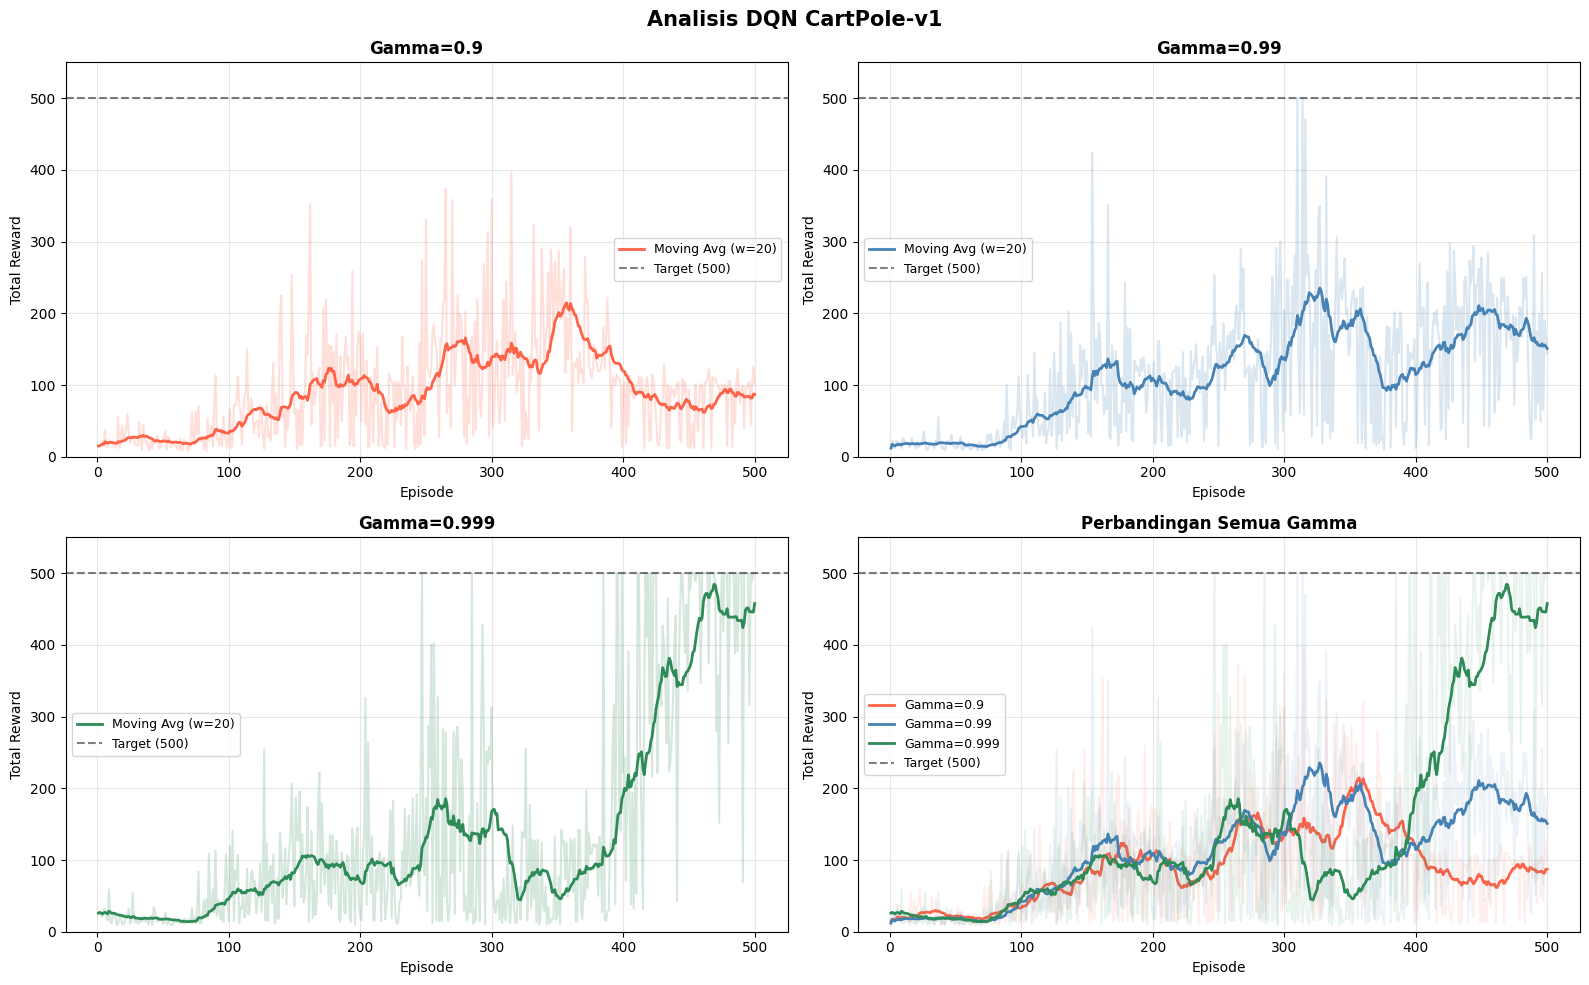


                          STATISTIK TRAINING                          
Gamma         Rata² Total   Rata² 50 Ep Terakhir   Max Reward Ep Terbaik
----------------------------------------------------------------------
Gamma=0.9            90.9                   82.3          397        315
Gamma=0.99          114.0                  165.6          500        310
Gamma=0.999         144.4                  454.8          500        247

          ANALISIS KONVERGENSI (Reward >= 400 pertama kali)           
  Gamma=0.9     : Tidak pernah mencapai 400
  Gamma=0.99    : Episode ke-154
  Gamma=0.999   : Episode ke-247


In [45]:
# Visualisasi & Statistik — Perbandingan 3 Gamma
def moving_average(data, window=10):
    result = []
    for i in range(len(data)):
        start = max(0, i - window + 1)
        result.append(np.mean(data[start:i+1]))
    return result

# Data eksperimen
experiments = {
    "Gamma=0.9"   : (rewards_09,   'tomato'),
    "Gamma=0.99"  : (rewards_099,  'steelblue'),
    "Gamma=0.999" : (rewards_0999, 'seagreen'),
}

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle("Analisis DQN CartPole-v1", fontsize=15, fontweight='bold')

# Plot 1: Masing-masing Gamma
for idx, (label, (rewards, color)) in enumerate(experiments.items()):
    ax = axes[0][idx] if idx < 2 else axes[1][0]
    episodes = range(1, len(rewards) + 1)
    ma = moving_average(rewards, window=20)

    ax.plot(episodes, rewards, alpha=0.2, color=color)
    ax.plot(episodes, ma, color=color, linewidth=2, label=f'Moving Avg (w=20)')
    ax.axhline(y=500, color='black', linestyle='--', alpha=0.5, label='Target (500)')
    ax.set_title(label, fontsize=12, fontweight='bold')
    ax.set_xlabel('Episode')
    ax.set_ylabel('Total Reward')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)
    ax.set_ylim(0, 550)

# Plot 2: Semua Gamma dalam 1 grafik
ax_all = axes[1][1]
for label, (rewards, color) in experiments.items():
    episodes = range(1, len(rewards) + 1)
    ma = moving_average(rewards, window=20)
    ax_all.plot(episodes, rewards, alpha=0.1, color=color)
    ax_all.plot(episodes, ma, color=color, linewidth=2, label=label)

ax_all.axhline(y=500, color='black', linestyle='--', alpha=0.5, label='Target (500)')
ax_all.set_title("Perbandingan Semua Gamma", fontsize=12, fontweight='bold')
ax_all.set_xlabel('Episode')
ax_all.set_ylabel('Total Reward')
ax_all.legend(fontsize=9)
ax_all.grid(True, alpha=0.3)
ax_all.set_ylim(0, 550)

plt.tight_layout()
plt.savefig("dqn_training_curve.png", dpi=150, bbox_inches='tight')
plt.show()

print("\n" + "="*70)
print(f"{'STATISTIK TRAINING':^70}")
print("="*70)
print(f"{'Gamma':<12} {'Rata² Total':>12} {'Rata² 50 Ep Terakhir':>22} {'Max Reward':>12} {'Ep Terbaik':>10}")
print("-"*70)
for label, (rewards, _) in experiments.items():
    avg_total = np.mean(rewards)
    avg_last  = np.mean(rewards[-50:])
    max_r     = max(rewards)
    best_ep   = rewards.index(max_r) + 1
    print(f"{label:<12} {avg_total:>12.1f} {avg_last:>22.1f} {max_r:>12.0f} {best_ep:>10}")
print("="*70)

print(f"\n{'ANALISIS KONVERGENSI (Reward >= 400 pertama kali)':^70}")
print("="*70)
for label, (rewards, _) in experiments.items():
    converged = next((i+1 for i, r in enumerate(rewards) if r >= 400), None)
    if converged:
        print(f"  {label:<14}: Episode ke-{converged}")
    else:
        print(f"  {label:<14}: Tidak pernah mencapai 400")
print("="*70)

In [46]:
# Fungsi Rekam Episode sebagai GIF 
from matplotlib import animation
from IPython.display import HTML, display

def record_episode(policy_net, gamma_label="DQN", max_steps=500):
    env = gym.make("CartPole-v1", render_mode="rgb_array")
    state, _ = env.reset(seed=42)

    frames = []       
    total_reward = 0
    done = False
    step = 0

    while not done and step < max_steps:
        frame = env.render()
        frames.append(frame)

        action = select_action(state, policy_net, epsilon=0.0,
                               action_dim=env.action_space.n)

        state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated
        total_reward += reward
        step += 1

    env.close()
    print(f"Episode selesai | {gamma_label} | "
          f"Total Reward: {total_reward:.0f} | Steps: {step}")

    fig, ax = plt.subplots(figsize=(6, 4))
    ax.axis('off')
    fig.patch.set_facecolor('black')

    img_plot = ax.imshow(frames[0])
    title = ax.set_title(
        f"{gamma_label} | Step: 0 | Reward: 0",
        color='white', fontsize=10, pad=8
    )

    def update(i):
        img_plot.set_data(frames[i])
        title.set_text(f"{gamma_label} | Step: {i+1} | Reward: {i+1}")
        return [img_plot, title]

    anim = animation.FuncAnimation(
        fig,
        update,
        frames=len(frames),
        interval=30,      
        blit=True
    )

    plt.close(fig)  

    # Konversi animasi ke HTML5 video
    html_video = anim.to_jshtml()
    display(HTML(html_video))

In [47]:
print("=" * 50)
print("  VISUALISASI AGENT — GAMMA = 0.9")
print("=" * 50)
record_episode(net_09, gamma_label="Gamma=0.9")

  VISUALISASI AGENT — GAMMA = 0.9
Episode selesai | Gamma=0.9 | Total Reward: 500 | Steps: 500


In [48]:
print("\n" + "=" * 50)
print("  VISUALISASI AGENT — GAMMA = 0.99")
print("=" * 50)
record_episode(net_099, gamma_label="Gamma=0.99")



  VISUALISASI AGENT — GAMMA = 0.99
Episode selesai | Gamma=0.99 | Total Reward: 83 | Steps: 83


In [ ]:
print("\n" + "=" * 50)
print("  VISUALISASI AGENT — GAMMA = 0.999")
print("=" * 50)
record_episode(net_0999, gamma_label="Gamma=0.999")


  VISUALISASI AGENT — GAMMA = 0.999
Episode selesai | Gamma=0.999 | Total Reward: 136 | Steps: 136


: 